In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import os

for folder, subfolders, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(folder, file))


/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_sellers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_geolocation_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/product_category_name_translation.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv


In [2]:

import pandas as pd
import os

DATA = "/kaggle/input/datasets/olistbr/brazilian-ecommerce"

orders = pd.read_csv(f"{DATA}/olist_orders_dataset.csv")
items = pd.read_csv(f"{DATA}/olist_order_items_dataset.csv")
payments = pd.read_csv(f"{DATA}/olist_order_payments_dataset.csv")
customers = pd.read_csv(f"{DATA}/olist_customers_dataset.csv")
products = pd.read_csv(f"{DATA}/olist_products_dataset.csv")
reviews = pd.read_csv(f"{DATA}/olist_order_reviews_dataset.csv")
sellers = pd.read_csv(f"{DATA}/olist_sellers_dataset.csv")
translation = pd.read_csv(f"{DATA}/product_category_name_translation.csv")

print("DATA LOADED SUCCESSFULLY!")
print("-" * 40)

for name, df in {
    "Orders": orders,
    "Items": items,
    "Payments": payments,
    "Customers": customers,
    "Products": products,
    "Reviews": reviews,
    "Sellers": sellers,
}.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

display(orders.head())


DATA LOADED SUCCESSFULLY!
----------------------------------------
Orders: 99,441 rows, 8 columns
Items: 112,650 rows, 7 columns
Payments: 103,886 rows, 5 columns
Customers: 99,441 rows, 5 columns
Products: 32,951 rows, 9 columns
Reviews: 99,224 rows, 7 columns
Sellers: 3,095 rows, 4 columns


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:

# 1. Convert order dates to datetime
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# 2. Check data quality
print("DATA QUALITY REPORT")
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Missing purchase dates:",
      orders["order_purchase_timestamp"].isna().sum())
print("Missing order statuses:", orders["order_status"].isna().sum())

# 3. Calculate key order KPIs
total_orders = orders["order_id"].nunique()
delivered_orders = (orders["order_status"] == "delivered").sum()
cancelled_orders = (orders["order_status"] == "canceled").sum()

print("\nBUSINESS KPI REPORT")
print("Total unique orders:", f"{total_orders:,}")
print("Delivered orders:", f"{delivered_orders:,}")
print("Canceled orders:", f"{cancelled_orders:,}")
print("Delivery completion rate:",
      f"{delivered_orders / total_orders * 100:.2f}%")

# 4. Calculate gross item sales
gross_sales = items["price"].sum()

print("Gross item sales: R$", round(gross_sales, 2))
print("Total order-item records:", f"{len(items):,}")


DATA QUALITY REPORT
Duplicate order IDs: 0
Missing purchase dates: 0
Missing order statuses: 0

BUSINESS KPI REPORT
Total unique orders: 99,441
Delivered orders: 96,478
Canceled orders: 625
Delivery completion rate: 97.02%
Gross item sales: R$ 13591643.7
Total order-item records: 112,650


,month,gross_item_sales,orders
12,2017-10,664219.43,4568
13,2017-11,1010271.37,7451
14,2017-12,743914.17,5624
15,2018-01,950030.36,7220
16,2018-02,844178.71,6694
17,2018-03,983213.44,7188
18,2018-04,996647.75,6934
19,2018-05,996517.68,6853
20,2018-06,865124.31,6160
21,2018-07,895507.22,6273


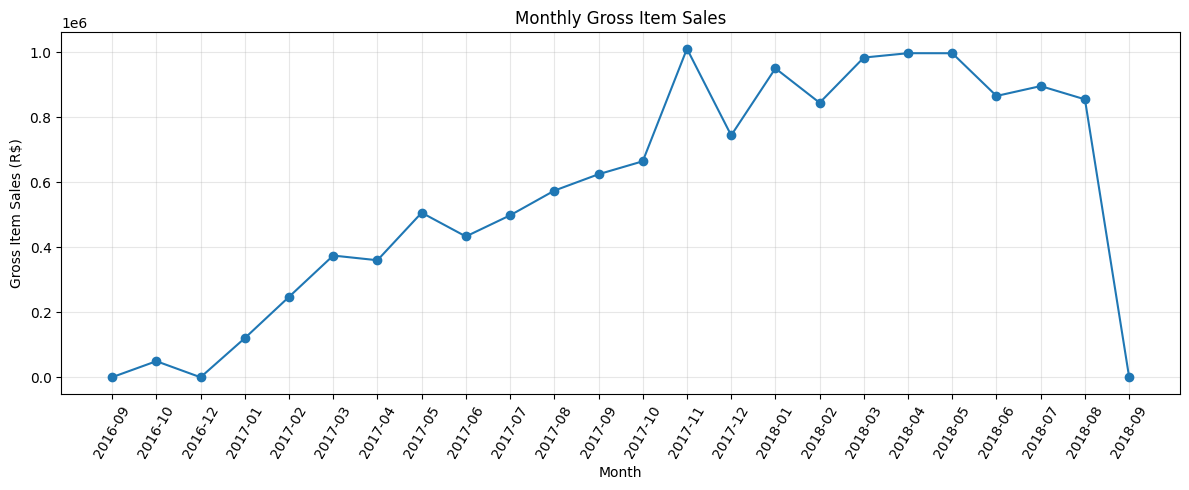

Highest-sales month: 2017-11
Gross item sales: R$ 1010271.37


In [7]:

import matplotlib.pyplot as plt

# Attach purchase date to each order item
sales_data = items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

sales_data["month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

# Monthly sales and order volume
monthly_sales = (
    sales_data.groupby("month")
    .agg(
        gross_item_sales=("price", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("month")
)

display(monthly_sales.tail(12))

# Plot monthly gross item sales
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["month"],
    monthly_sales["gross_item_sales"],
    marker="o"
)
plt.title("Monthly Gross Item Sales")
plt.xlabel("Month")
plt.ylabel("Gross Item Sales (R$)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Highest-sales month
best_month = monthly_sales.loc[
    monthly_sales["gross_item_sales"].idxmax()
]

print("Highest-sales month:", best_month["month"])
print("Gross item sales: R$", round(best_month["gross_item_sales"], 2))


,category,gross_item_sales,order_count,items_sold
0,health_beauty,1258681.34,8836,9670
1,watches_gifts,1205005.68,5624,5991
2,bed_bath_table,1036988.68,9417,11115
3,sports_leisure,988048.97,7720,8641
4,computers_accessories,911954.32,6689,7827
5,furniture_decor,729762.49,6449,8334
6,cool_stuff,635290.85,3632,3796
7,housewares,632248.66,5884,6964
8,auto,592720.11,3897,4235
9,garden_tools,485256.46,3518,4347


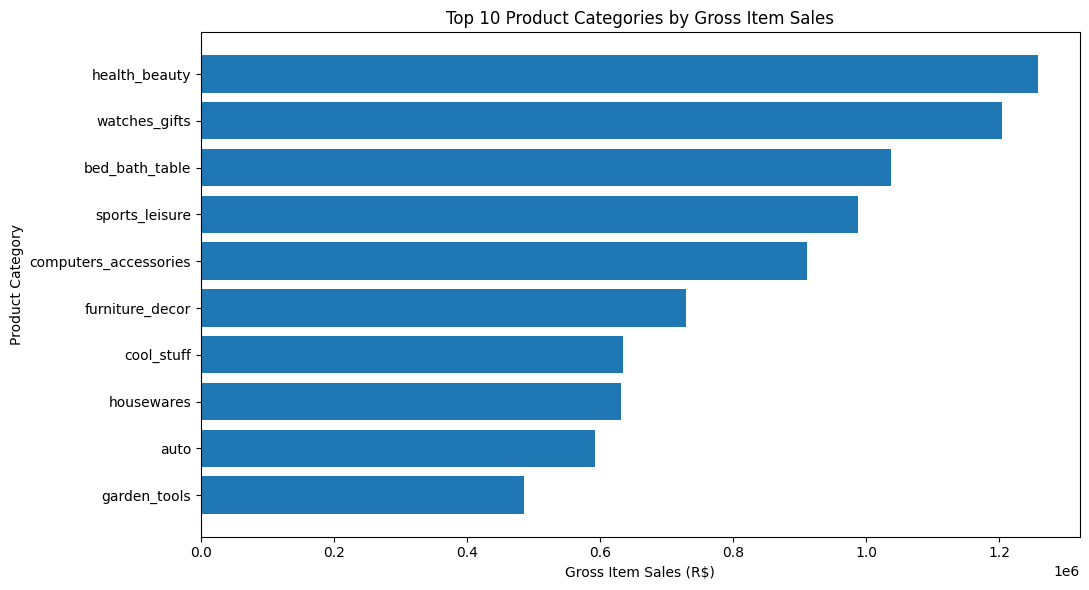

In [8]:

# Translate category names into English
products_en = products.merge(
    translation,
    on="product_category_name",
    how="left"
)

products_en["category"] = (
    products_en["product_category_name_english"]
    .fillna(products_en["product_category_name"])
    .fillna("unknown")
)

# Join product categories to order items
category_data = items.merge(
    products_en[["product_id", "category"]],
    on="product_id",
    how="left"
)

category_data["category"] = category_data["category"].fillna("unknown")

# Calculate sales and number of orders per category
top_categories = (
    category_data.groupby("category")
    .agg(
        gross_item_sales=("price", "sum"),
        order_count=("order_id", "nunique"),
        items_sold=("order_id", "count")
    )
    .sort_values("gross_item_sales", ascending=False)
    .head(10)
    .reset_index()
)

display(top_categories)

# Visualize the top 10 categories
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))
plt.barh(
    top_categories["category"][::-1],
    top_categories["gross_item_sales"][::-1]
)
plt.title("Top 10 Product Categories by Gross Item Sales")
plt.xlabel("Gross Item Sales (R$)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()



In [11]:

# Convert delivery dates
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce"
)
orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"], errors="coerce"
)
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

# Use delivered orders with all required dates
delivered = orders[
    (orders["order_status"] == "delivered") &
    orders["order_purchase_timestamp"].notna() &
    orders["order_delivered_customer_date"].notna() &
    orders["order_estimated_delivery_date"].notna()
].copy()

# Calculate delivery duration and lateness
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] -
    delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivered["late"] = (
    delivered["order_delivered_customer_date"] >
    delivered["order_estimated_delivery_date"]
)

print("DELIVERY PERFORMANCE")
print("Delivered orders with complete dates:", len(delivered))
print("Average delivery time (days):",
      round(delivered["delivery_days"].mean(), 2))
print("Median delivery time (days):",
      round(delivered["delivery_days"].median(), 2))
print("Late orders:", int(delivered["late"].sum()))
print("Late delivery rate (%):",
      round(delivered["late"].mean() * 100, 2))

# Visualize delivery duration
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(delivered["delivery_days"].dropna(), bins=40)
plt.title("Distribution of Delivery Time")
plt.xlabel("Days from purchase to delivery")
plt.ylabel("Number of delivered orders")
plt.tight_layout()
plt.show()


DELIVERY PERFORMANCE
Delivered orders with complete dates: 96470
Average delivery time (days): 12.56
Median delivery time (days): 10.22
Late orders: 7826
Late delivery rate (%): 8.11


KeyboardInterrupt: 

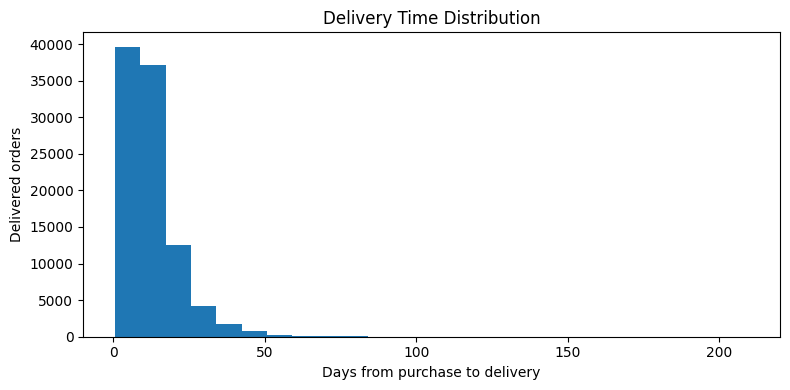

In [13]:

import matplotlib.pyplot as plt

plt.close("all")
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(delivered["delivery_days"].dropna(), bins=25)
ax.set_title("Delivery Time Distribution")
ax.set_xlabel("Days from purchase to delivery")
ax.set_ylabel("Delivered orders")
fig.tight_layout()
display(fig)
plt.close(fig)


CUSTOMER REVIEW DISTRIBUTION


,number_of_reviews
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


Average review score: 4.09
Total review records: 99224
Missing review scores: 0
Percentage of 1- or 2-star reviews: 14.69 %


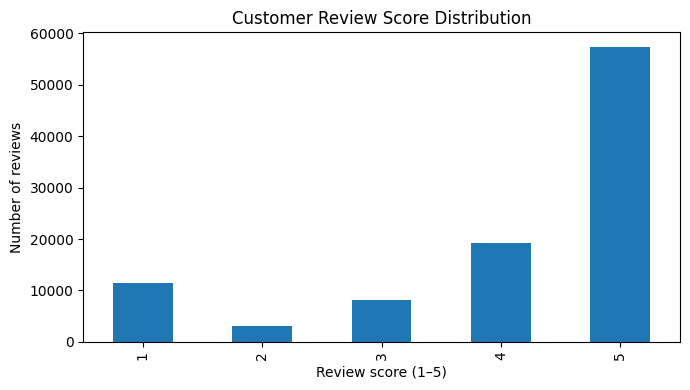

In [14]:

# Customer review analysis
review_summary = reviews["review_score"].value_counts().sort_index()

print("CUSTOMER REVIEW DISTRIBUTION")
display(review_summary.rename("number_of_reviews").to_frame())

print("Average review score:",
      round(reviews["review_score"].mean(), 2))
print("Total review records:", len(reviews))
print("Missing review scores:",
      reviews["review_score"].isna().sum())
print("Percentage of 1- or 2-star reviews:",
      round(reviews["review_score"].isin([1, 2]).mean() * 100, 2), "%")

ax = review_summary.plot(kind="bar", figsize=(7, 4))
ax.set_title("Customer Review Score Distribution")
ax.set_xlabel("Review score (1–5)")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()


In [17]:

# Connect order reviews with delivery performance
review_delivery = reviews.merge(
    delivered[
        ["order_id", "delivery_days", "late"]
    ],
    on="order_id",
    how="inner"
)

review_delivery["review_group"] = review_delivery["late"].map({
    True: "Late delivery",
    False: "On-time delivery"
})

# Compare ratings by delivery status
comparison = (
    review_delivery.groupby("review_group")
    .agg(
        average_review=("review_score", "mean"),
        review_records=("review_score", "count")
    )
    .round(2)
)

print("CUSTOMER SATISFACTION BY DELIVERY STATUS")
display(comparison)

# Calculate low-rating percentages
review_delivery["low_rating"] = review_delivery["review_score"].isin([1, 2])

low_rating_comparison = (
    review_delivery.groupby("review_group")["low_rating"]
    .mean().mul(100).round(2)
    .rename("low_rating_percentage")
)

display(low_rating_comparison)


CUSTOMER SATISFACTION BY DELIVERY STATUS


,average_review,review_records
review_group,,
Late delivery,2.57,7700
On-time delivery,4.29,88653


review_group
Late delivery       54.03
On-time delivery     9.23
Name: low_rating_percentage, dtype: float64

In [18]:

## Customer Satisfaction Analysis

### Key Findings
- Average review score for late deliveries: 2.57/5.
- Average review score for on-time deliveries: 4.29/5.
- Low-rating percentage for late deliveries: 54.03%.
- Low-rating percentage for on-time deliveries: 9.23%.

### Business Insight
Late deliveries are strongly associated with lower customer ratings in this dataset.

### Recommendation
Improve delivery-time estimates, monitor delayed shipments, and proactively notify customers about delays.

### Limitation
This analysis shows an association, not proof that late delivery alone causes poor reviews.


SyntaxError: invalid syntax (2606675896.py, line 4)


## Customer Satisfaction Analysis

### Key Findings
- Average review score for late deliveries: 2.57/5
- Average review score for on-time deliveries: 4.29/5
- Low-rating percentage for late deliveries: 54.03%
- Low-rating percentage for on-time deliveries: 9.23%

### Business Insight
Late deliveries are associated with lower customer ratings.

### Recommendation
Improve delivery estimates, monitor delayed shipments, and notify customers proactively about delays.

### Limitation
This analysis shows an association; it does not prove that late delivery alone causes poor reviews.


In [24]:

import pandas as pd
import matplotlib.pyplot as plt

# Build a KPI summary using your existing analysis
kpis = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Delivered Orders",
        "Canceled Orders",
        "Gross Item Sales (R$)",
        "Average Review Score",
        "Late Delivery Rate (%)"
    ],
    "Value": [
        total_orders,
        delivered_orders,
        cancelled_orders,
        round(gross_sales, 2),
        round(reviews["review_score"].mean(), 2),
        round(delivered["late"].mean() * 100, 2)
    ]
})

display(kpis)


,Metric,Value
0,Total Orders,99441.00
1,Delivered Orders,96478.00
2,Canceled Orders,625.00
3,Gross Item Sales (R$),13591643.70
4,Average Review Score,4.09
5,Late Delivery Rate (%),8.11



# Brazilian E-Commerce Data Analytics Project

## 1. Objective
Analyze e-commerce sales, product category performance, delivery efficiency, and customer satisfaction using the Olist public dataset.

## 2. Tools Used
- Python
- Pandas
- Matplotlib
- Kaggle Notebooks

## 3. Key Business Metrics
- Total orders: 99,441
- Delivered orders: 96,478
- Canceled orders: 625
- Gross item sales: R$13,591,643.70
- Average customer review: 4.09/5
- Late delivery rate: 8.11%

## 4. Key Findings
- Health & Beauty had the highest gross item sales among the analyzed categories.
- November 2017 was the highest-sales month in the calculated monthly results.
- Late deliveries had an average review score of 2.57, compared with 4.29 for on-time deliveries.
- Low ratings (1–2 stars) occurred in 54.03% of late-delivery reviews versus 9.23% of on-time-delivery reviews.

## 5. Recommendations
1. Monitor delayed orders and identify recurring delivery bottlenecks.
2. Notify customers proactively when estimated delivery dates change.
3. Review category-level sales trends when planning inventory and marketing.
4. Investigate low customer ratings to identify opportunities to improve the customer experience.

## 6. Limitations
- The dataset contains historical, anonymized marketplace data.
- Gross item sales are not net revenue or profit.
- Associations between delivery timing and reviews do not establish causation.
- Results should be validated before making operational decisions.


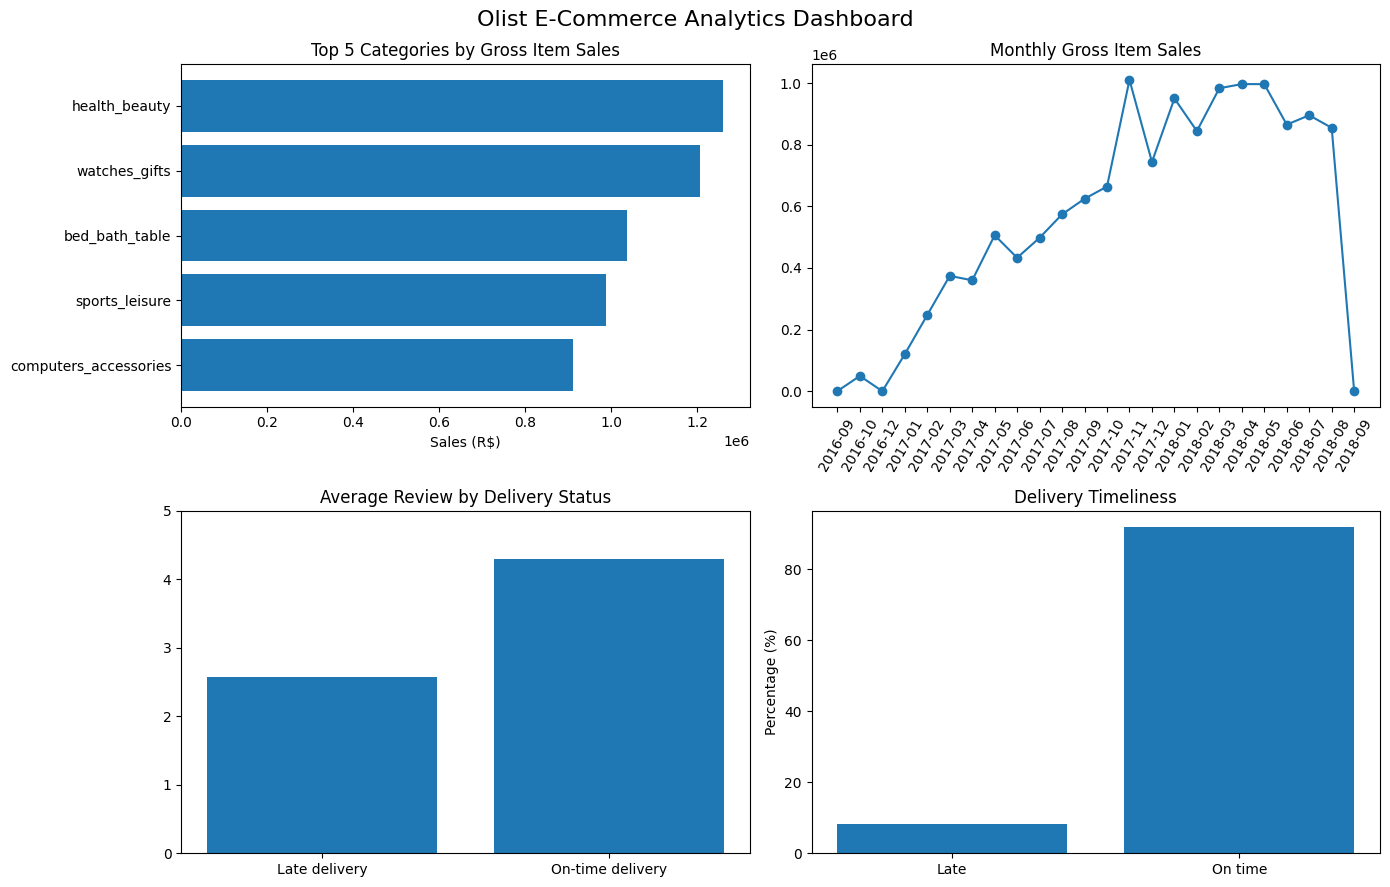

In [25]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Top 5 product categories
top5 = top_categories.head(5)
axes[0, 0].barh(
    top5["category"][::-1],
    top5["gross_item_sales"][::-1]
)
axes[0, 0].set_title("Top 5 Categories by Gross Item Sales")
axes[0, 0].set_xlabel("Sales (R$)")

# 2. Monthly sales
axes[0, 1].plot(
    monthly_sales["month"],
    monthly_sales["gross_item_sales"],
    marker="o"
)
axes[0, 1].set_title("Monthly Gross Item Sales")
axes[0, 1].tick_params(axis="x", rotation=60)

# 3. Review scores
axes[1, 0].bar(
    ["Late delivery", "On-time delivery"],
    [2.57, 4.29]
)
axes[1, 0].set_title("Average Review by Delivery Status")
axes[1, 0].set_ylim(0, 5)

# 4. Delivery status
axes[1, 1].bar(
    ["Late", "On time"],
    [8.11, 91.89]
)
axes[1, 1].set_title("Delivery Timeliness")
axes[1, 1].set_ylabel("Percentage (%)")

fig.suptitle("Olist E-Commerce Analytics Dashboard", fontsize=16)
fig.tight_layout()
display(fig)
plt.close(fig)


In [26]:

# Validate the dataset's date range and monthly order counts

print("Earliest purchase:",
      orders["order_purchase_timestamp"].min())

print("Latest purchase:",
      orders["order_purchase_timestamp"].max())

print("\nOrders by month:")
print(
    orders.dropna(subset=["order_purchase_timestamp"])
    .assign(month=lambda df:
        df["order_purchase_timestamp"].dt.to_period("M").astype(str))
    .groupby("month")["order_id"]
    .nunique()
    .tail(6)
)


Earliest purchase: 2016-09-04 21:15:19
Latest purchase: 2018-10-17 17:30:18

Orders by month:
month
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Name: order_id, dtype: int64


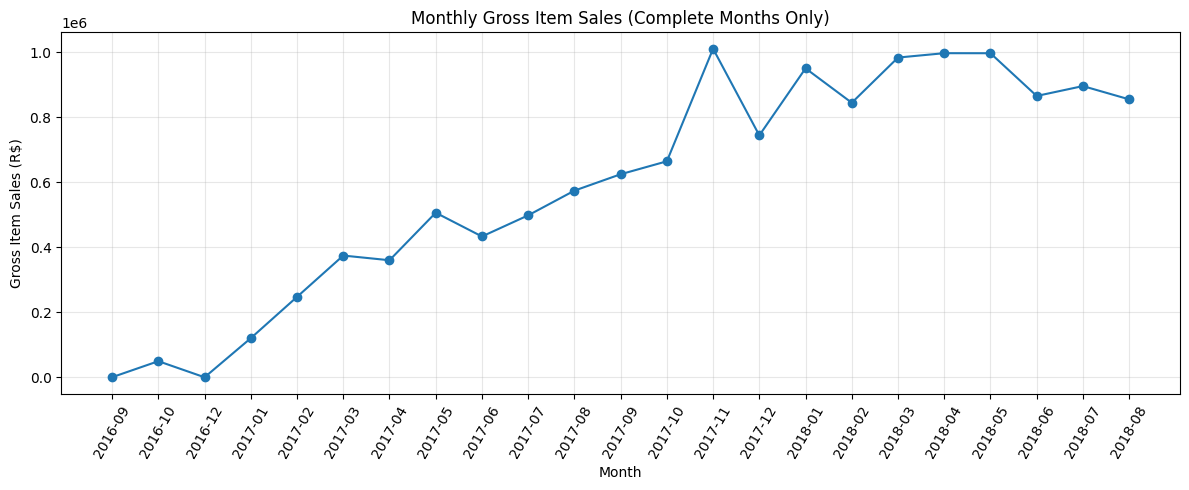

Months included: 23
Highest-sales month: 2017-11


In [27]:

# Keep only complete months through August 2018
monthly_sales_complete = monthly_sales[
    monthly_sales["month"] <= "2018-08"
].copy()

# Display the corrected monthly trend
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    monthly_sales_complete["month"],
    monthly_sales_complete["gross_item_sales"],
    marker="o"
)
ax.set_title("Monthly Gross Item Sales (Complete Months Only)")
ax.set_xlabel("Month")
ax.set_ylabel("Gross Item Sales (R$)")
ax.tick_params(axis="x", rotation=60)
ax.grid(True, alpha=0.3)
fig.tight_layout()
display(fig)
plt.close(fig)

print("Months included:", len(monthly_sales_complete))
print("Highest-sales month:",
      monthly_sales_complete.loc[
          monthly_sales_complete["gross_item_sales"].idxmax(), "month"
      ])



# Brazilian E-Commerce Data Analytics

## Project Overview
Analyzed the Olist Brazilian E-Commerce Public Dataset to understand sales performance, product categories, delivery efficiency, and customer satisfaction.

## Tools
- Python
- Pandas
- Matplotlib
- Kaggle Notebooks

## Key Findings
- 99,441 unique orders analyzed.
- Gross item sales of R$13.59 million.
- Average customer review score of 4.09/5.
- Late delivery rate of 8.11% among delivered orders with complete dates.
- Health & Beauty was the highest-sales category among the categories analyzed.
- November 2017 had the highest monthly gross item sales in the analysis.
- Late-delivery reviews averaged 2.57/5, versus 4.29/5 for on-time deliveries.

## Business Recommendations
1. Investigate causes of delayed deliveries.
2. Notify customers when shipments are delayed.
3. Monitor product category performance for inventory and marketing decisions.
4. Investigate low review scores to identify customer-experience improvements.

## Data Source
Olist Brazilian E-Commerce Public Dataset:
https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

## Limitations
The data is historical and anonymized. Gross item sales are not profit or net revenue. Relationships between delivery timing and reviews do not prove causation.
